# B. MODELING MENGGUNAKAN TRANSFER LEARNING (PRE-TRAINED MODEL)

> Notebook ini mengerjakan alur dari awal: **scraping → pembersihan data → fine-tuning IndoBERT → evaluasi**.

**Perbedaan dengan versi sebelumnya:**
- Data di-scraping ulang dan dicek, karena file skor 1 ClassDojo sebelumnya berisi ulasan PrimaKu.
- Data duplikat dibuang **sebelum** split, supaya test set tidak bocor.
- Training memakai *early stopping* dan model dipilih dari *validation loss*.
- Ada kurva loss dan perbandingan akurasi train, validation, dan test untuk mengecek overfitting.

## 1.Mount Drive & Pindah Direktori

Mount Google Drive dan pindah ke direktori kerja.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Penjelasan:** Menghubungkan Google Colab dengan Google Drive agar hasil scraping dan model tersimpan.

In [ ]:
%cd '/content/drive/MyDrive/KULIAH/CAPSTONE/PSC1/UTS'

/content/drive/MyDrive/KULIAH/CAPSTONE/PSC1/UTS


**Penjelasan:** Membuat (jika belum ada) dan berpindah ke folder kerja `psc1`.

## 2.Import Library

In [ ]:
!pip install google-play-scraper transformers datasets evaluate accelerate -q

**Penjelasan:** Menginstall library yang dibutuhkan untuk scraping dan fine-tuning.

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('Library siap!')

Library siap!


**Penjelasan:** Import library untuk pengolahan data, visualisasi, pembagian data, dan evaluasi.

## 3.Scraping Ulasan

Mengambil ulasan **ClassDojo** dan **PrimaKu** dengan skor **1** (negatif) dan **5** (positif) dari Google Play Store. Setiap hasil disimpan ke file CSV masing-masing, lengkap dengan `reviewId` dan nama aplikasi.

> Jalankan sel scraping **sekali saja**. Setelah file CSV tersimpan, langsung lanjut ke bagian 4 supaya datanya tidak berubah-ubah.

In [ ]:
from google_play_scraper import Sort, reviews

apps = {'mobilejkn': 'app.bpjs.mobile', 'primaku': 'com.primaku.app'}
semua = []

for nama_app, id_app in apps.items():
    for skor in [1, 5]:
        result, _ = reviews(
            id_app,
            lang='id',
            country='id',
            sort=Sort.NEWEST,
            count=4000,
            filter_score_with=skor
        )
        d = pd.DataFrame(result)[['reviewId', 'content', 'score', 'at']]
        d['app'] = nama_app
        d.to_csv(f'ulasan-skor{skor}_{nama_app}.csv', index=False)
        semua.append(d)
        print(nama_app, '| skor', skor, '|', len(d), 'ulasan')

pd.concat(semua, ignore_index=True).to_csv('semua_ulasan_gabungan_final.csv', index=False)

mobilejkn | skor 1 | 4000 ulasan
mobilejkn | skor 5 | 4000 ulasan
primaku | skor 1 | 490 ulasan
primaku | skor 5 | 1496 ulasan


**Penjelasan:** Perulangan mengambil ulasan terbaru berbahasa Indonesia untuk tiap kombinasi aplikasi dan skor. Hasilnya disimpan per file, lalu digabung menjadi `semua_ulasan_gabungan_final.csv`.

## 4.Load Dataset

In [ ]:
df = pd.read_csv('semua_ulasan_gabungan_final.csv')

print('Jumlah data:', df.shape[0])
df.groupby(['app', 'score']).size()

Jumlah data: 9986


app        score
mobilejkn  1        4000
           5        4000
primaku    1         490
           5        1496
dtype: int64

**Penjelasan:** Membaca dataset gabungan hasil scraping dan melihat jumlah ulasan per aplikasi dan skor.

In [ ]:
# Satu reviewId tidak boleh muncul di lebih dari satu file/grup
cek = df.groupby('reviewId')[['app', 'score']].nunique().max(axis=1)
assert (cek == 1).all(), 'Ada reviewId yang sama di file berbeda, periksa hasil scraping!'
print('Cek data lolos.')

Cek data lolos.


**Penjelasan:** Mengecek bahwa tidak ada ulasan yang sama muncul di file berbeda. Pengecekan ini dibuat karena pada versi sebelumnya ada file yang isinya tertukar.

## 5.Pelabelan Sentimen

- **Skor 1** = Negatif (label 0)
- **Skor 5** = Positif (label 1)

In [ ]:
def pelabelan(score):
    if score == 1:
        return 0  # Negatif
    else:
        return 1  # Positif

df['label'] = df['score'].apply(pelabelan)
df['label'].value_counts()

,count
label,
1,5496
0,4490


**Penjelasan:** Mengubah skor menjadi label biner, lalu menampilkan jumlah tiap label.

## 6.Preprocessing Data

Preprocessing dibuat ringan untuk IndoBERT: membersihkan URL, simbol, huruf berulang, dan menormalkan kata slang. **Stemming dan stopword removal tidak dipakai** supaya kata negasi seperti "tidak" tetap ada.

In [ ]:
# Kamus slangword (opsional, kalau file kamus_slang.csv ada di folder)
slang_mapping = {
    'gak': 'tidak', 'ga': 'tidak', 'gk': 'tidak', 'tdk': 'tidak', 'ngga': 'tidak', 'nggak': 'tidak',
    'gabisa': 'tidak bisa', 'gbs': 'tidak bisa',
    'yg': 'yang', 'dgn': 'dengan', 'utk': 'untuk', 'dr': 'dari',
    'klo': 'kalau', 'klw': 'kalau', 'kalo': 'kalau',
    'jd': 'jadi', 'jgn': 'jangan', 'bbrp': 'beberapa',
    'notif': 'notifikasi', 'apk': 'aplikasi', 'app': 'aplikasi',
    'bgt': 'banget', 'bener': 'benar', 'beneran': 'benaran'
}

try:
    kslang = pd.read_csv('kamus_slang.csv')
    slang_mapping.update(dict(zip(kslang['slang'], kslang['baku'])))
    print('Kamus slangword dimuat, jumlah:', len(slang_mapping))
except FileNotFoundError:
    print('kamus_slang.csv tidak ditemukan, memakai kamus bawaan.')

Kamus slangword dimuat, jumlah: 88


**Penjelasan:** Menyiapkan kamus untuk mengubah kata tidak baku (misal "gak", "bgt") menjadi bentuk baku.

In [ ]:
def preprocess_for_bert(text):
    if pd.isna(text):
        return ''

    # 1. Hapus URL/Link & Mention/HTML
    text = re.sub(r'https?://\S+|www\.\S+', ' ', str(text))
    text = re.sub(r'@[A-Za-z0-9_]+|<.*?>', ' ', text)

    # 2. Rapikan huruf berulang berlebih (misal: 'baguuus' -> 'bagus')
    text = re.sub(r'([a-zA-Z])\1{2,}', r'\1', text)

    # 3. Bersihkan simbol aneh tapi PERTAHANKAN huruf, angka, dan tanda baca sentimen (. , ! ?)
    text = re.sub(r'[^a-zA-Z0-9\s.,!?]', ' ', text)

    # 4. Normalisasi kata slang (tanpa menghapus satu kata pun)
    words = text.split()
    normalized_words = []
    for w in words:
        match = re.match(r'^([a-zA-Z0-9]+)([,.!?]*)$', w)
        if match:
            core, punct = match.groups()
            normalized_words.append(slang_mapping.get(core.lower(), core) + punct)
        else:
            normalized_words.append(slang_mapping.get(w.lower(), w))

    # 5. Rapikan spasi
    return re.sub(r'\s+', ' ', ' '.join(normalized_words)).strip()

df['clean_text'] = df['content'].apply(preprocess_for_bert)
df[['content', 'clean_text']].sample(5, random_state=42)

,content,clean_text
1558,tolong lah di perbaiki daftar bolak balik masa...,tolong lah di perbaiki daftar bolak balik masa...
3057,mau login ajah ribet nya minta ampun ..,mau login ajah ribet nya minta ampun ..
8657,keren sangat membantu,keren sangat membantu
5798,Sangat membantu,Sangat membantu
35,ferifikasi wajah gagal terus,ferifikasi wajah gagal terus


**Penjelasan:** Fungsi `preprocess_for_bert` merapikan teks tanpa menghapus kata. Tanda baca `. , ! ?` dipertahankan karena bisa menandakan emosi.

## 7.Hapus Data Duplikat

Teks yang sama di data latih dan data uji membuat hasil evaluasi terlalu bagus, karena model tinggal "mengingat". Jadi duplikat dibuang **sebelum** data dibagi.

In [ ]:
# Kunci pembanding: huruf kecil tanpa tanda baca
df['key'] = df['clean_text'].str.lower().str.replace(r'[^a-z0-9 ]', ' ', regex=True).str.split().str.join(' ')
print('Data awal                    :', len(df))

df = df[df['key'] != '']                      # teks kosong / hanya simbol
print('Setelah buang teks kosong    :', len(df))

df = df.drop_duplicates('reviewId')           # ulasan yang sama persis
print('Setelah buang reviewId ganda :', len(df))

# Teks sama tapi beda label -> pakai label mayoritas
df['label'] = df.groupby('key')['label'].transform(lambda s: s.mode()[0])

df = df.drop_duplicates('key').reset_index(drop=True)   # teks duplikat
print('Setelah buang teks duplikat  :', len(df))

Data awal                    : 9986
Setelah buang teks kosong    : 9912
Setelah buang reviewId ganda : 9912
Setelah buang teks duplikat  : 7508


**Penjelasan:** Data dibersihkan bertahap dan jumlahnya ditampilkan di tiap tahap. Teks yang sama dengan label berbeda (misal "bagus" yang sekali dipakai untuk ulasan bintang 1) diberi label mayoritasnya, lalu hanya satu salinan yang disimpan.

In [ ]:
pd.crosstab(df['app'], df['label'].map({0: 'Negatif', 1: 'Positif'}), margins=True)

label,Negatif,Positif,All
app,,,
mobilejkn,3830,2248,6078
primaku,467,963,1430
All,4297,3211,7508


**Penjelasan:** Komposisi data setelah dibersihkan. Perhatikan apakah kedua aplikasi punya ulasan negatif **dan** positif.

In [ ]:
# Seberapa jauh nama aplikasi saja bisa menebak label?
mayoritas = df['label'].value_counts(normalize=True).max()
label_app = df.groupby('app')['label'].agg(lambda s: s.mode()[0])
tebak_app = (df['app'].map(label_app) == df['label']).mean()

print('Akurasi tebak kelas mayoritas :', round(mayoritas, 4))
print('Akurasi tebak dari nama app   :', round(tebak_app, 4))

Akurasi tebak kelas mayoritas : 0.5723
Akurasi tebak dari nama app   : 0.6384


**Penjelasan:** Jika tebakan dari nama aplikasi jauh lebih tinggi daripada tebakan kelas mayoritas, berarti aplikasi dan label saling berkaitan. Model bisa saja belajar "mengenali aplikasi", bukan sentimen. Karena itu hasil evaluasi dilihat juga per aplikasi di bagian 12.

## 7,5 Balancing Data (Under Sampling)

In [ ]:
# Balancing dataset dengan undersampling mengikuti label dengan jumlah terkecil
min_class_size = df['label'].value_counts().min()
df = df.groupby('label').apply(lambda x: x.sample(n=min_class_size, random_state=42)).reset_index(drop=True)
print('Jumlah data setelah undersampling:', len(df))
print(df['label'].value_counts())

Jumlah data setelah undersampling: 6422
label
0    3211
1    3211
Name: count, dtype: int64


/tmp/ipykernel_559/1366499795.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('label').apply(lambda x: x.sample(n=min_class_size, random_state=42)).reset_index(drop=True)


dilakukan undersampling mengikuti label dengan jumlah paling sedikit (positif = 3211)

## 8.Split Data

Data dibagi 80% train, 10% validation, dan 10% test dengan `stratify` berdasarkan kombinasi **aplikasi dan label**, sehingga proporsinya sama di ketiga bagian.

In [ ]:
df['strata'] = df['app'] + df['label'].astype(str)

train_val, test = train_test_split(df, test_size=0.1, random_state=42, stratify=df['strata'])
train, val = train_test_split(train_val, test_size=0.11, random_state=42, stratify=train_val['strata'])

# Pastikan tidak ada teks yang sama antar bagian
assert not (set(train['key']) & set(test['key'])), 'Ada teks sama di train dan test'
assert not (set(train['key']) & set(val['key'])), 'Ada teks sama di train dan val'

print(f'Train: {len(train)}, Val: {len(val)}, Test: {len(test)}')

Train: 5143, Val: 636, Test: 643


**Penjelasan:** Dua `assert` memastikan tidak ada teks yang sama antara train dengan val/test. Kalau ada, sel akan berhenti dengan pesan error.

## 9.Transfer Learning dengan Fine-Tuning (IndoBERT)

Fine-tuning model **IndoBERT** (`indolem/indobert-base-uncased`) untuk klasifikasi sentimen biner.

> Aktifkan GPU lewat *Runtime → Change runtime type → T4 GPU* sebelum menjalankan bagian ini.

### 9.1 Import Library

In [ ]:
import torch
import evaluate
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, EarlyStoppingCallback)
from datasets import Dataset

print('GPU tersedia:', torch.cuda.is_available())

GPU tersedia: True


**Penjelasan:** Import library HuggingFace. Output `GPU tersedia: True` berarti GPU sudah aktif.

### 9.2 Prepare Data for Training

In [ ]:
# Create HuggingFace Dataset
train_dataset = Dataset.from_dict({'text': train['clean_text'].tolist(), 'label': train['label'].tolist()})
val_dataset = Dataset.from_dict({'text': val['clean_text'].tolist(), 'label': val['label'].tolist()})
test_dataset = Dataset.from_dict({'text': test['clean_text'].tolist(), 'label': test['label'].tolist()})

# Load tokenizer
model_name = 'indolem/indobert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Tokenize function (padding dilakukan per batch oleh data collator)
def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=256)

train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

print('Tokenization selesai!')

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/234k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/5143 [00:00<?, ? examples/s]

Map:   0%|          | 0/636 [00:00<?, ? examples/s]

Map:   0%|          | 0/643 [00:00<?, ? examples/s]

Tokenization selesai!


**Penjelasan:** Mengubah DataFrame menjadi format Dataset HuggingFace, lalu mengubah teks menjadi token yang dipahami IndoBERT.

### 9.3 Load Model untuk Fine-Tuning

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: 'Negatif', 1: 'Positif'},
    label2id={'Negatif': 0, 'Positif': 1},
    ignore_mismatched_sizes=True
)
print('Model IndoBERT siap untuk fine-tuning!')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  445MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model IndoBERT siap untuk fine-tuning!


**Penjelasan:** Memuat IndoBERT untuk klasifikasi 2 kelas. Peringatan tentang bobot `classifier` yang baru diinisialisasi itu normal.

### 9.4 Handle Imbalanced Data

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train['label']),
    y=train['label']
)
class_weights_dict = {i: w for i, w in enumerate(class_weights)}
print('Class weights:', class_weights_dict)

Class weights: {0: np.float64(1.000194476857254), 1: np.float64(0.9998055987558321)}


**Penjelasan:** Menghitung bobot kelas supaya kelas yang jumlahnya lebih sedikit mendapat perhatian lebih besar saat training.

### 9.5 Define Metrics & Custom Trainer

In [ ]:
metric = evaluate.load('accuracy')

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return metric.compute(predictions=predictions, references=labels)

# Custom Trainer dengan class weights
class CustomTrainer(Trainer):
    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        if class_weights is not None:
            self.class_weights = torch.tensor(class_weights, dtype=torch.float32).to(self.args.device)
        else:
            self.class_weights = None

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

print('Custom Trainer dengan class weights siap!')

Custom Trainer dengan class weights siap!


**Penjelasan:** `compute_metrics` menghitung akurasi di tiap epoch. `CustomTrainer` sama seperti versi sebelumnya: menghitung loss dengan bobot kelas.

### 9.6 Training Configuration

- **Learning rate:** 2e-5
- **Epoch maksimum:** 5, dengan **early stopping** (berhenti jika validation loss tidak membaik selama 2 epoch)
- **Model terbaik:** dipilih dari **validation loss** terendah
- **Batch size:** 16
- **Warmup:** 10% dari total langkah, lalu learning rate turun linear

In [ ]:
import inspect, math

batch = 16
epoch_maks = 10
total_langkah = math.ceil(len(train_dataset) / batch) * epoch_maks

all_args = {
    'output_dir': '/content/results',
    'learning_rate': 2e-5,                      # standar fine-tuning BERT (rentang umum 2e-5 s.d. 5e-5)
    'num_train_epochs': epoch_maks,             # batas atas, early stopping yang menghentikan lebih awal
    'per_device_train_batch_size': batch,
    'per_device_eval_batch_size': 32,
    'warmup_steps': int(0.1 * total_langkah),   # warmup 10% dari total langkah
    'lr_scheduler_type': 'linear',              # learning rate turun linear setelah warmup
    'weight_decay': 0.01,
    'logging_strategy': 'epoch',
    'save_strategy': 'epoch',
    'save_total_limit': 1,
    'load_best_model_at_end': True,
    'metric_for_best_model': 'loss',            # validation loss terendah
    'greater_is_better': False,
    'fp16': torch.cuda.is_available(),
    'report_to': 'none',
    'seed': 42
}

# Nama parameter evaluasi berbeda antar versi transformers
sig = inspect.signature(TrainingArguments.__init__).parameters
if 'eval_strategy' in sig:
    all_args['eval_strategy'] = 'epoch'
else:
    all_args['evaluation_strategy'] = 'epoch'

valid_args = {k: v for k, v in all_args.items() if k in sig}
training_args = TrainingArguments(**valid_args)

trainer = CustomTrainer(
    class_weights=list(class_weights_dict.values()),
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)
print('Trainer siap dijalankan!')

Trainer siap dijalankan!


**Penjelasan:** Menjalankan training. Tabel yang muncul menampilkan training loss dan validation loss tiap epoch. Training bisa berhenti sebelum epoch 5 karena early stopping.

### 9.7 Fine-Tuning (Training)

In [ ]:
print('Memulai fine-tuning IndoBERT...')
trainer.train()
print('Fine-tuning selesai!')

Memulai fine-tuning IndoBERT...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.179235,0.333847,0.924528
2,0.228574,0.277373,0.924528
3,0.198120,0.313353,0.927673
4,0.155589,0.271943,0.933962
5,0.128394,0.388681,0.921384
6,0.091323,0.363848,0.924528


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning selesai!


**Penjelasan:** Menjalankan training. Tabel yang muncul menampilkan training loss dan validation loss tiap epoch. Training bisa berhenti sebelum epoch 6 karena early stopping.

## 10.Cek Overfitting

Overfitting terjadi saat model sangat bagus di data latih tetapi tidak membaik di data baru. Tandanya: **training loss terus turun, sementara validation loss berhenti turun atau naik**.

In [ ]:
log = pd.DataFrame(trainer.state.log_history)
tr = log[log['loss'].notna()][['epoch', 'loss']]
ev = log[log['eval_loss'].notna()][['epoch', 'eval_loss', 'eval_accuracy']]

hist = tr.merge(ev, on='epoch')
hist.columns = ['epoch', 'train_loss', 'val_loss', 'val_acc']
hist

,epoch,train_loss,val_loss,val_acc
0,1.0,0.179235,0.333847,0.924528
1,2.0,0.228574,0.277373,0.924528
2,3.0,0.198120,0.313353,0.927673
3,4.0,0.155589,0.271943,0.933962
4,5.0,0.128394,0.388681,0.921384
5,6.0,0.091323,0.363848,0.924528


**Penjelasan:** Tabel loss dan akurasi validasi per epoch, diambil dari log training.

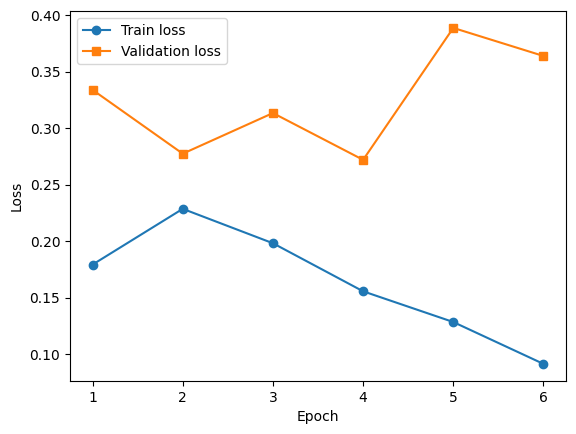

Epoch dengan validation loss terendah: 4.0 dari 6.0 epoch


In [ ]:
plt.plot(hist['epoch'], hist['train_loss'], 'o-', label='Train loss')
plt.plot(hist['epoch'], hist['val_loss'], 's-', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

best_epoch = hist.loc[hist['val_loss'].idxmin(), 'epoch']
print('Epoch dengan validation loss terendah:', best_epoch, 'dari', hist['epoch'].max(), 'epoch')

**Penjelasan:** Grafik kurva loss. Jika garis validation mendatar atau naik sementara garis train terus turun, berarti ada overfitting. Model akhir yang dipakai adalah bobot dari epoch dengan validation loss terendah.

In [ ]:
akurasi = {}
for nama, ds in [('Train', train_dataset), ('Validation', val_dataset), ('Test', test_dataset)]:
    pr = trainer.predict(ds)
    akurasi[nama] = accuracy_score(pr.label_ids, np.argmax(pr.predictions, axis=1))
    print(f'Akurasi {nama:10s}: {akurasi[nama]:.4f}')

print('Selisih Train - Validation:', round(akurasi['Train'] - akurasi['Validation'], 4))

Akurasi Train     : 0.9774


Akurasi Validation: 0.9340


Akurasi Test      : 0.9207
Selisih Train - Validation: 0.0435


**Penjelasan:** Model akhir diuji pada ketiga set dengan cara yang sama. Selisih akurasi train dan validation yang besar (di atas sekitar 0,05) adalah tanda overfitting. Angka ini hanya patokan kasar, dibaca bersama grafik di atas.

## 11.Evaluasi pada Test Set

In [ ]:
# Prediksi pada test set
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=1)
labels = predictions.label_ids

print('=== HASIL EVALUASI INDOBERT (FINE-TUNED) ===')
print(classification_report(labels, preds, target_names=['Negatif', 'Positif'], digits=4))

# Interval kepercayaan 95% (Wilson) karena test set kecil
n = len(labels)
k = (preds == labels).sum()
p = k / n
z = 1.96
tengah = (p + z**2 / (2 * n)) / (1 + z**2 / n)
lebar = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f'Akurasi: {k}/{n} = {p:.4f} | 95% CI: {tengah - lebar:.4f} - {tengah + lebar:.4f}')

=== HASIL EVALUASI INDOBERT (FINE-TUNED) ===
              precision    recall  f1-score   support

     Negatif     0.8974    0.9503    0.9231       322
     Positif     0.9470    0.8910    0.9181       321

    accuracy                         0.9207       643
   macro avg     0.9222    0.9206    0.9206       643
weighted avg     0.9222    0.9207    0.9206       643

Akurasi: 592/643 = 0.9207 | 95% CI: 0.8972 - 0.9392


**Penjelasan:** Menampilkan precision, recall, dan F1 per kelas. Karena jumlah data test kecil, akurasi disertai **interval kepercayaan 95%**, yaitu rentang akurasi yang masuk akal. Angka tunggal bisa terlihat lebih presisi daripada kenyataannya.

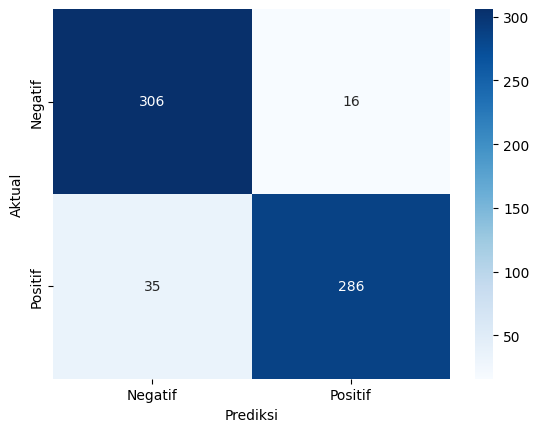

In [ ]:
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Positif'], yticklabels=['Negatif', 'Positif'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

**Penjelasan:** *Confusion matrix*: baris adalah label sebenarnya, kolom adalah prediksi model.

## 12.Evaluasi per Aplikasi & Analisis Kesalahan

In [ ]:
hasil = test.copy()
hasil['pred'] = preds
hasil['benar'] = hasil['pred'] == hasil['label']

# Akurasi per aplikasi dan label
hasil.groupby(['app', 'label'])['benar'].agg(['mean', 'count']).round(4)

mean  count
app       label               
mobilejkn 0      0.9510    286
          1      0.8711    225
primaku   0      0.9444     36
          1      0.9375     96

**Penjelasan:** Akurasi dipisah per aplikasi dan label (0 = Negatif, 1 = Positif). Kalau model jauh lebih baik di satu aplikasi, berarti performanya belum merata.

In [ ]:
hasil['yakin'] = torch.softmax(torch.tensor(predictions.predictions), dim=1).max(dim=1).values.numpy()

print('Jumlah salah prediksi:', (~hasil['benar']).sum(), 'dari', len(hasil))
hasil[~hasil['benar']].sort_values('yakin', ascending=False)[['app', 'label', 'pred', 'yakin', 'content']].head(10)

Jumlah salah prediksi: 51 dari 643


,app,label,pred,yakin,content
385,mobilejkn,0,1,0.999076,ini cukup mematu aku.
958,mobilejkn,0,1,0.998952,mantap aplikasi sampah
2433,mobilejkn,0,1,0.998448,lola bgt
1923,mobilejkn,0,1,0.998377,ingin mengetahui jam kontrol di rumah sakit Me...
47,primaku,0,1,0.998306,nanti kalo bagus aku tambahin lagi bintangnya
749,mobilejkn,0,1,0.998012,kurang baik
275,mobilejkn,0,1,0.996913,Mengapa Vivo y91 Android 8.1.0 nggak support l...
2501,primaku,0,1,0.996752,Segini saja dulu karna belum tau aplikasi ini ...
2479,mobilejkn,0,1,0.993996,"Sekarang, bayar BPJS kena biaya ADMIN"
4649,mobilejkn,1,0,0.991067,"aplikasi kagak jelas monyet, kode Verifikasi a..."


**Penjelasan:** Daftar kesalahan dengan tingkat keyakinan tertinggi. Biasanya berisi ulasan ambigu, sarkasme, atau rating yang tidak cocok dengan isi teksnya. Cocok dipakai untuk bahan analisis di laporan.

## 13.Uji Coba Kalimat Baru & Simpan Model

In [ ]:
from transformers import pipeline

clf = pipeline('sentiment-analysis', model=trainer.model, tokenizer=tokenizer)

sample_texts = [
    'aplikasi ini sangat bagus dan sangat membantu!',
    'tidak bagus',
    'aplikasi jelek banget tidak bisa dibuka sama sekali!'
]

for text in sample_texts:
    res = clf(preprocess_for_bert(text))[0]
    print(f"Teks  : {text}")
    print(f"Hasil : {res['label']} (Confidence: {round(res['score'] * 100, 2)}%)\n")

Teks  : aplikasi ini sangat bagus dan sangat membantu!
Hasil : Positif (Confidence: 99.91%)

Teks  : tidak bagus
Hasil : Negatif (Confidence: 98.45%)

Teks  : aplikasi jelek banget tidak bisa dibuka sama sekali!
Hasil : Negatif (Confidence: 99.13%)



**Penjelasan:** Mencoba model pada kalimat baru, termasuk kalimat dengan negasi ("tidak bagus"). Kalimat diproses dengan `preprocess_for_bert` yang sama seperti saat training.

In [ ]:
trainer.save_model('model_final')
tokenizer.save_pretrained('model_final')
print('Model tersimpan di folder model_final')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model tersimpan di folder model_final



## 13,5. Ekspor Model ke Format tunggal .pkl (Pickle)

Di sini kita mengemas objek **model** (arsitektur & bobot) dan **tokenizer** ke dalam satu berkas `.pkl` agar praktis saat dimuat kembali di lingkungan lain.

In [ ]:
import pickle
import torch

# Menyiapkan data yang ingin dikemas
model_pack = {
    'model_state_dict': trainer.model.state_dict(),
    'config': trainer.model.config,
    'tokenizer': tokenizer
}

# Menyimpan objek ke dalam file .pkl
pkl_filename = 'model_final_indobert.pkl'
with open(pkl_filename, 'wb') as f:
    pickle.dump(model_pack, f)

print(f"Model berhasil diekspor ke berkas tunggal: {pkl_filename}")

Model berhasil diekspor ke berkas tunggal: model_final_indobert.pkl


**Penjelasan:** Menyimpan model terbaik (bobot dari epoch dengan validation loss terendah) beserta tokenizer ke folder `model_final` di Drive.

## 14.Penutup

In [ ]:
print('Akurasi Train / Val / Test :', {k: round(v, 4) for k, v in akurasi.items()})
print(f'Akurasi test               : {p:.4f} (95% CI {tengah - lebar:.3f} - {tengah + lebar:.3f})')
print('Epoch terbaik              :', best_epoch, 'dari', hist['epoch'].max())

Akurasi Train / Val / Test : {'Train': 0.9774, 'Validation': 0.934, 'Test': 0.9207}
Akurasi test               : 0.9207 (95% CI 0.897 - 0.939)
Epoch terbaik              : 4.0 dari 6.0


```markdown
## 16. Optimasi Alur & Visualisasi Tambahan
Berikut adalah sel perbaikan untuk merapikan kode visualisasi performa model serta alternatif proses penyimpanan agar lebih lengkap.
```

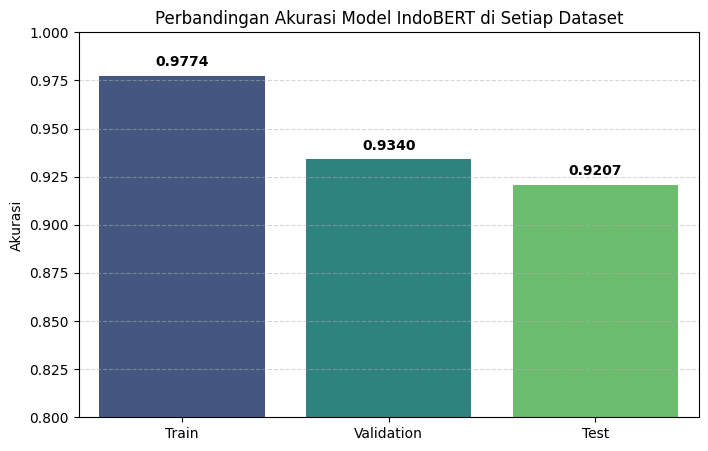

In [ ]:
# Visualisasi yang lebih rapi untuk perbandingan akurasi Train, Validation, dan Test
categories = list(akurasi.keys())
values = list(akurasi.values())

plt.figure(figsize=(8, 5))
sns.barplot(x=categories, y=values, palette='viridis', hue=categories, legend=False)
plt.ylim(0.8, 1.0)
for i, v in enumerate(values):
    plt.text(i, v + 0.005, f"{v:.4f}", ha='center', fontweight='bold')
plt.title('Perbandingan Akurasi Model IndoBERT di Setiap Dataset')
plt.ylabel('Akurasi')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Penjelasan:** Ringkasan angka hasil run ini. Gunakan angka dari output ini (bukan angka dari versi lama) saat menulis laporan.

**Hal yang perlu ditulis di kesimpulan laporan:**
- Epoch tempat model terbaik dipilih dan apakah ada tanda overfitting (lihat grafik loss dan selisih akurasi train-validation).
- Akurasi test **beserta interval kepercayaannya**.
- Performa per aplikasi, dan contoh kesalahan prediksi.
- Keterbatasan: data kecil, label otomatis dari rating, tidak ada kelas netral, hanya dua aplikasi, dan hasil scraping berubah mengikuti waktu pengambilan data.

##15.Push Huggingface


kode ini untuk push model langsung ke huggingface


In [ ]:
import os
from google.colab import userdata
from huggingface_hub import login, create_repo
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1. Autentikasi Login ke Hugging Face menggunakan Secrets
print("🔑 Memulai login ke Hugging Face...")
hf_token = userdata.get('HF_TOKEN')
login(hf_token)

# 2. Tentukan nama repository (Format: username/nama-model)
repo_id = "dimeneid/kawantumbuh-sentimen"
print(f"📦 Menyiapkan repository: {repo_id}")

# Membuat repository baru secara otomatis (jika belum ada)
create_repo(repo_id, exist_ok=True, repo_type="model")

# 3. Muat model dan tokenizer yang sudah di-training dari Google Drive
# Sesuaikan BEST_MODEL_PATH dengan lokasi folder model kamu
BEST_MODEL_PATH = "/content/drive/MyDrive/KULIAH/CAPSTONE/PSC1/UTS/model_final"
print("🧠 Memuat model terbaik dari Google Drive...")
model_terbaik = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_PATH)
tokenizer_terbaik = AutoTokenizer.from_pretrained(BEST_MODEL_PATH)

# 4. Upload (Push) ke Hugging Face Hub
print(f"🚀 Mulai mengunggah model dan tokenizer ke Hugging Face...")
model_terbaik.push_to_hub(repo_id)
tokenizer_terbaik.push_to_hub(repo_id)

print(f"\n✅ Selesai! Model siap digunakan dan bisa diakses di: https://huggingface.co/{repo_id}")

🔑 Memulai login ke Hugging Face...
📦 Menyiapkan repository: dimeneid/kawantumbuh-sentimen
🧠 Memuat model terbaik dari Google Drive...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

🚀 Mulai mengunggah model dan tokenizer ke Hugging Face...


README.md:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ij5j3g5/model.safetensors:   0%|          |  560kB /  442MB            

Validating                    :           |   0%            


✅ Selesai! Model siap digunakan dan bisa diakses di: https://huggingface.co/dimeneid/kawantumbuh-sentimen
